# ЛР2. Разведочный анализ и подготовка данных

**Датасет:** `data/marketing_data.zip` → `marketing_data.csv`. Это 2240 клиентов магазина: возраст, образование, семья, доход,
траты по категориям товаров, каналы покупок, отклик на маркетинговые кампании.

**Задание:**
1. импортировать датасет;
2. найти пропуски и аномальные значения (статистикой и графиками), заполнить пропуски, устранить выбросы и проверить результат графиками;
3. сгенерировать новые признаки (не меньше двух) и закодировать категориальные признаки (OHE, бинаризация и др.);
4. стандартизировать и нормализовать данные.

| Столбец | Смысл |
|---|---|
| `ID` | номер клиента |
| `Year_Birth` | год рождения |
| `Education` | образование: Basic, Graduation (бакалавр), 2n Cycle / Master (магистр), PhD |
| `Marital_Status` | семейное положение |
| `Income` | годовой доход семьи, $ |
| `Kidhome`, `Teenhome` | сколько в семье детей и подростков |
| `Dt_Customer` | дата регистрации клиента |
| `Recency` | сколько дней прошло с последней покупки |
| `MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts`, `MntGoldProds` | траты за 2 года по категориям, $ |
| `NumDealsPurchases` | покупки со скидкой |
| `NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases` | покупки через сайт, каталог, в магазине |
| `NumWebVisitsMonth` | заходы на сайт за последний месяц |
| `AcceptedCmp1`…`AcceptedCmp5`, `Response` | принял ли клиент предложение 1–5-й и последней кампании (0/1) |
| `Complain` | жаловался ли за 2 года (0/1) |
| `Country` | страна |

## 0. Проверка окружения

Ноутбук запускается в виртуальном окружении `.venv`. Ячейка ниже показывает, **какой Python сейчас работает** и версии библиотек.
Путь должен заканчиваться на `.venv/bin/python`: это значит, что среда активирована и ядро (kernel) использует её.

In [40]:
import sys
print("Python:", sys.version.split()[0])
print("Интерпретатор:", sys.executable)
print("Среда активирована:", ".venv" in sys.executable or sys.prefix != sys.base_prefix)

Python: 3.8.10
Интерпретатор: /Users/fenikhey/Documents/ML/Labs/Lab2/lab2_marketing/.venv/bin/python
Среда активирована: True


## 0.1 Библиотеки

- **pandas** — таблицы (`DataFrame`): загрузка, фильтры, группировки;
- **numpy** — математика над массивами;
- **matplotlib / seaborn** — графики;
- **scikit-learn** — кодирование и масштабирование признаков.

In [41]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, Binarizer)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

MAIN = "#3b6fb6"     # один цвет для всех «одиночных» графиков
GREY = "#9aa5b4"     # цвет для «до обработки»

def thousands(ax, axis="x"):
    # подписи оси в тысячах: 60000 -> 60k, чтобы подписи не налезали друг на друга
    fmt = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k")
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(fmt)

for lib in (pd, np, matplotlib, sns, sklearn):
    print(f"{lib.__name__:12} {lib.__version__}")

pandas       2.0.3
numpy        1.24.4
matplotlib   3.7.5
seaborn      0.13.2
sklearn      1.3.2


## 1. Импорт датасета

`pd.read_csv` читает CSV прямо из zip-архива, если в архиве один файл. Путь относительный: архив лежит в папке `data` рядом с ноутбуком.

In [42]:
df = pd.read_csv("data/marketing_data.zip")
print("Размер:", df.shape)
df.head()

Размер: (2240, 28)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,"$84,835.00",0,0,6/16/14,0,189,104,379,111,189,218,1,4,4,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,"$57,091.00",0,0,6/15/14,0,464,5,64,7,0,37,1,7,3,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,"$67,267.00",0,1,5/13/14,0,134,11,59,15,2,30,1,3,2,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,"$32,474.00",1,1,5/11/14,0,10,0,1,0,0,0,1,1,0,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,"$21,474.00",1,0,4/8/14,0,6,16,24,11,0,34,2,3,1,2,7,1,0,0,0,0,1,0,SP


Названия столбцов проверяем сразу: у дохода имя записано с пробелами, `' Income '`. Из-за этого `df["Income"]` не сработал бы.
`str.strip()` убирает пробелы по краям всех имён.

In [43]:
print(list(df.columns)[:6])
df.columns = df.columns.str.strip()
print(list(df.columns)[:6])

['ID', 'Year_Birth', 'Education', 'Marital_Status', ' Income ', 'Kidhome']
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome']


In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2187 entries, 0 to 2186
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2187 non-null   int64         
 1   Year_Birth           2187 non-null   int64         
 2   Education            2187 non-null   object        
 3   Marital_Status       2187 non-null   object        
 4   Income               2187 non-null   float64       
 5   Kidhome              2187 non-null   int64         
 6   Teenhome             2187 non-null   int64         
 7   Dt_Customer          2187 non-null   datetime64[ns]
 8   Recency              2187 non-null   int64         
 9   MntWines             2187 non-null   int64         
 10  MntFruits            2187 non-null   int64         
 11  MntMeatProducts      2187 non-null   int64         
 12  MntFishProducts      2187 non-null   int64         
 13  MntSweetProducts     2187 non-nul

**Что видно в `info()`:**
- `Income` и `Dt_Customer` хранятся как **строки** (`object` / `str`), а не как число и дата. С ними нельзя считать, сначала их нужно преобразовать;
- у `Income` непустых значений меньше 2240, значит, есть пропуски.

### 1.1 Приведение типов

**Доход.** Строка `"$84,835.00 "` содержит знак доллара, запятую-разделитель тысяч и пробел. Убираем лишние символы регулярным выражением
`[$, ]` («любой из символов: доллар, запятая, пробел») и переводим в число. Пустые строки превращаются в `NaN` (пропуск).

**Дата.** `pd.to_datetime` с форматом `%m/%d/%y` — месяц/день/год из двух цифр, например `6/16/14`.

In [45]:
raw_income = df["Income"].copy()
df["Income"] = pd.to_numeric(df["Income"].str.replace(r"[$, ]", "", regex=True), errors="coerce")
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%m/%d/%y")

pd.DataFrame({"было": raw_income.head(), "стало": df["Income"].head()})

,было,стало
0,"$84,835.00",84835.0
1,"$57,091.00",57091.0
2,"$67,267.00",67267.0
3,"$32,474.00",32474.0
4,"$21,474.00",21474.0


In [46]:
print("Тип Income:", df["Income"].dtype, "| тип Dt_Customer:", df["Dt_Customer"].dtype)
print("Даты регистрации: с", df["Dt_Customer"].min().date(), "по", df["Dt_Customer"].max().date())
raw = df.copy()      # копия до очистки: пригодится для графиков «до / после»
df.describe().T.round(1)

Тип Income: float64 | тип Dt_Customer: datetime64[ns]
Даты регистрации: с 2012-07-30 по 2014-06-29


,count,mean,min,25%,50%,75%,max,std
ID,2240.0,5592.159821,0.0,2828.25,5458.5,8427.75,11191.0,3246.662198
Year_Birth,2240.0,1968.805804,1893.0,1959.0,1970.0,1977.0,1996.0,11.984069
Income,2216.0,52247.251354,1730.0,35303.0,51381.5,68522.0,666666.0,25173.076661
Kidhome,2240.0,0.444196,0.0,0.0,0.0,1.0,2.0,0.538398
Teenhome,2240.0,0.50625,0.0,0.0,0.0,1.0,2.0,0.544538
Dt_Customer,2240,2013-07-10 10:01:42.857142784,2012-07-30 00:00:00,2013-01-16 00:00:00,2013-07-08 12:00:00,2013-12-30 06:00:00,2014-06-29 00:00:00,NaN
Recency,2240.0,49.109375,0.0,24.0,49.0,74.0,99.0,28.962453
MntWines,2240.0,303.935714,0.0,23.75,173.5,504.25,1493.0,336.597393
MntFruits,2240.0,26.302232,0.0,1.0,8.0,33.0,199.0,39.773434
MntMeatProducts,2240.0,166.95,0.0,16.0,67.0,232.0,1725.0,225.715373


`describe()` — первый инструмент поиска аномалий: смотрим на `min` и `max` и спрашиваем себя, бывает ли такое в жизни.

- `Year_Birth` min = **1893**: в 2014 году (данные собраны в 2012–2014) клиенту было бы 121 год;
- `Income` max = **666 666**: остальные доходы не выше ~163 000. Похоже на ввод «шестёрками» вместо реального числа;
- `NumWebPurchases` до 27 и `NumCatalogPurchases` до 28 при медиане 4 и 2;
- среднее у трат (`Mnt...`) заметно больше медианы (50%): распределения сильно скошены вправо.

## 2. Пропуски, дубликаты и аномальные значения

### 2.1 Дубликаты

`ID` у всех клиентов разный, но если его не учитывать, некоторые строки полностью совпадают: тот же год рождения, доход,
все траты и покупки до единицы. Скорее всего, это один клиент, записанный дважды.
`duplicated()` помечает повторы (True для второго и следующих вхождений).

In [47]:
dup_mask = df.drop(columns="ID").duplicated()
print("Полных дубликатов (без учёта ID):", dup_mask.sum())
df[df.drop(columns="ID").duplicated(keep=False)].sort_values(["Year_Birth", "Income"]).head(4)

Полных дубликатов (без учёта ID): 47


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
1948,455,1946,PhD,Married,51012.0,0,0,2013-04-18,86,102,9,63,2,9,24,1,4,1,4,6,0,0,0,0,0,0,0,SP
1949,7592,1946,PhD,Married,51012.0,0,0,2013-04-18,86,102,9,63,2,9,24,1,4,1,4,6,0,0,0,0,0,0,0,SP
1217,202,1948,PhD,Widow,82032.0,0,0,2014-04-05,54,332,194,377,149,125,57,0,4,6,7,1,0,0,0,0,0,0,0,IND
1218,9589,1948,PhD,Widow,82032.0,0,0,2014-04-05,54,332,194,377,149,125,57,0,4,6,7,1,0,0,0,0,0,0,0,IND


### 2.2 Пропуски

`isna()` возвращает таблицу True/False (True — пропуск), `.sum()` считает пропуски по столбцам.

In [48]:
missing = df.isna().sum()
pd.DataFrame({"пропусков": missing, "%": (missing / len(df) * 100).round(2)})[missing > 0]

,пропусков,%
Income,24,1.07


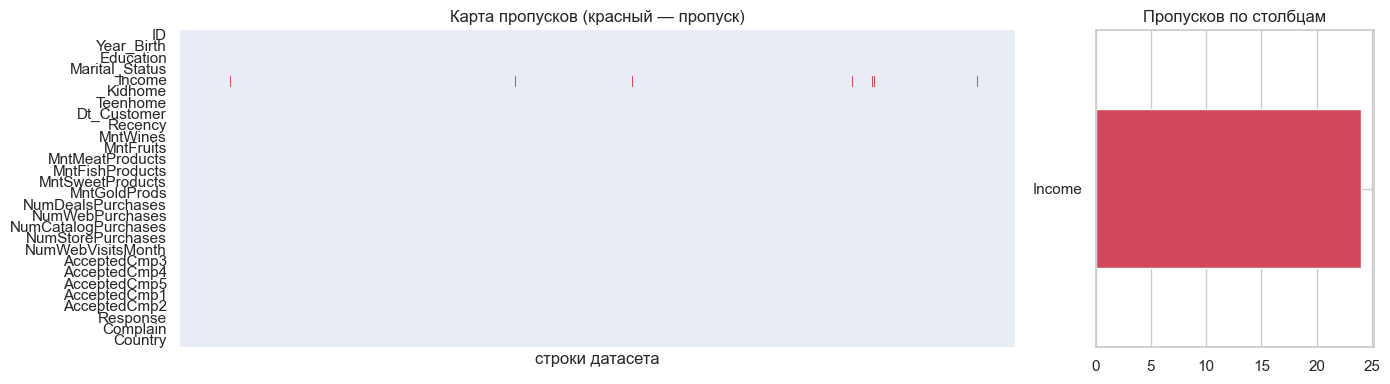

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})
sns.heatmap(df.isna().T, cbar=False, cmap=["#e8edf5", "#d1495b"], ax=axes[0], yticklabels=True)
axes[0].set_xticks([])
axes[0].set_title("Карта пропусков (красный — пропуск)")
axes[0].set_xlabel("строки датасета")
(missing[missing > 0]).plot.barh(ax=axes[1], color="#d1495b")
axes[1].set_title("Пропусков по столбцам")
plt.tight_layout(); plt.show()

Пропуски есть только в `Income`: 24 значения (около 1%). Удалять эти строки не обязательно. Доход сильно зависит от образования,
поэтому заполнять будем **медианой дохода по уровню образования**.

### 2.3 Аномалии: статистические методы

**Метод межквартильного размаха (IQR).** Q1 и Q3 — 25-й и 75-й перцентили, IQR = Q3 − Q1.
Выброс — значение меньше Q1 − 1.5·IQR или больше Q3 + 1.5·IQR. На этом правиле построены «усы» BoxPlot.

**Метод Z-оценки.** z = (x − среднее) / стандартное отклонение, выброс при |z| > 3.
Хорошо работает для распределений, похожих на нормальное. Само среднее и std сдвигаются от выбросов, поэтому IQR надёжнее.

In [50]:
num_cols = ["Year_Birth", "Income", "Recency", "MntWines", "MntMeatProducts", "MntGoldProds",
            "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases",
            "NumWebVisitsMonth"]

def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for col in num_cols:
    s = df[col].dropna()
    lo, hi = iqr_bounds(s)
    z = (s - s.mean()) / s.std()
    rows.append({"признак": col,
                 "граница IQR снизу": round(lo, 1), "граница IQR сверху": round(hi, 1),
                 "выбросов по IQR": int(((s < lo) | (s > hi)).sum()),
                 "выбросов по |z|>3": int((z.abs() > 3).sum()),
                 "max": s.max()})
pd.DataFrame(rows)

,признак,граница IQR снизу,граница IQR сверху,выбросов по IQR,выбросов по |z|>3,max
0,Year_Birth,1932.0,2004.0,3,3,1996.0
1,Income,-14525.5,118350.5,8,8,666666.0
2,Recency,-51.0,149.0,0,0,99.0
3,MntWines,-697.0,1225.0,35,16,1493.0
4,MntMeatProducts,-308.0,556.0,175,37,1725.0
5,MntGoldProds,-61.5,126.5,207,44,362.0
6,NumDealsPurchases,-2.0,6.0,86,32,15.0
7,NumWebPurchases,-4.0,12.0,4,4,27.0
8,NumCatalogPurchases,-6.0,10.0,23,4,28.0
9,NumStorePurchases,-4.5,15.5,0,0,13.0


**Важно:** не всё, что IQR назвал выбросом, — ошибка. Траты (`Mnt...`) скошены вправо: богатых покупателей немного, но они настоящие,
поэтому IQR находит у вина и мяса сотни «выбросов». Удалять их — значит выбросить лучших клиентов.
Поэтому статистику дополняем **логическими проверками**, то есть здравым смыслом про предметную область:

In [51]:
mnt_cols = [c for c in df.columns if c.startswith("Mnt")]
purchase_cols = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
REF_YEAR = df["Dt_Customer"].max().year          # 2014 — год последней регистрации

def logical_checks(d):
    total_purch = d[purchase_cols].sum(axis=1)
    total_spent = d[mnt_cols].sum(axis=1)
    return pd.Series({
        "дубликаты строк (без ID)": int(d.drop(columns="ID").duplicated().sum()),
        "пропуски Income": int(d["Income"].isna().sum()),
        f"возраст > 90 лет (Year_Birth < {REF_YEAR - 90})": int((d["Year_Birth"] < REF_YEAR - 90).sum()),
        "Income > 200 000": int((d["Income"] > 200_000).sum()),
        "Marital_Status: YOLO / Absurd / Alone": int(d["Marital_Status"].isin(["YOLO", "Absurd", "Alone"]).sum()),
        "покупок 0, а траты > 0": int(((total_purch == 0) & (total_spent > 0)).sum()),
        "NumWebPurchases > 20": int((d["NumWebPurchases"] > 20).sum()),
        "NumCatalogPurchases > 20": int((d["NumCatalogPurchases"] > 20).sum()),
    }, name="строк")

logical_checks(df).to_frame()

,строк
дубликаты строк (без ID),47
пропуски Income,24
возраст > 90 лет (Year_Birth < 1924),3
Income > 200 000,1
Marital_Status: YOLO / Absurd / Alone,7
"покупок 0, а траты > 0",6
NumWebPurchases > 20,4
NumCatalogPurchases > 20,4


In [52]:
print(df["Marital_Status"].value_counts().to_string())
print()
print(df["Education"].value_counts().to_string())

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
YOLO          2
Absurd        2

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54


**Категориальные аномалии:**
- `YOLO` («живём один раз») и `Absurd` — явный мусор при заполнении анкеты, а не семейное положение;
- `Alone` («один») — по смыслу то же, что `Single`;
- в `Education` значение `2n Cycle` — это европейское название магистратуры («второй цикл» Болонской системы), то есть то же, что `Master`.

### 2.4 Аномалии: графики

**Гистограммы** показывают форму распределения: длинный хвост или одиночный столбик далеко в стороне выдают выбросы.

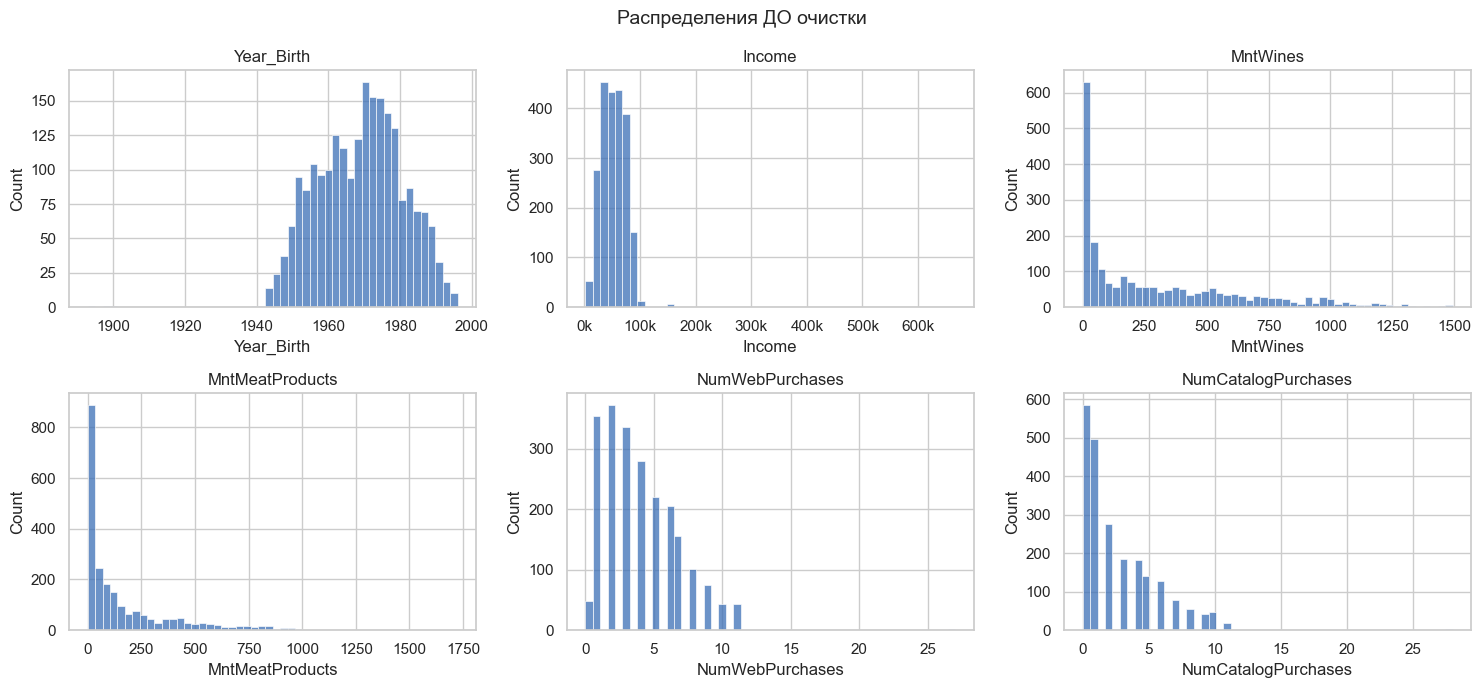

In [53]:
cols = ["Year_Birth", "Income", "MntWines", "MntMeatProducts", "NumWebPurchases", "NumCatalogPurchases"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(df[col].dropna(), bins=50, ax=ax, color=MAIN)
    ax.set_title(col)
    if col == "Income":
        thousands(ax)
plt.suptitle("Распределения ДО очистки", fontsize=14)
plt.tight_layout(); plt.show()

**BoxPlot (ящик с усами):** ящик — от Q1 до Q3, линия внутри — медиана, усы — до 1.5·IQR, точки за усами — кандидаты в выбросы.
У `Year_Birth` три точки далеко внизу (1893–1900), у `Income` одна точка 666 666 сплющивает весь ящик.

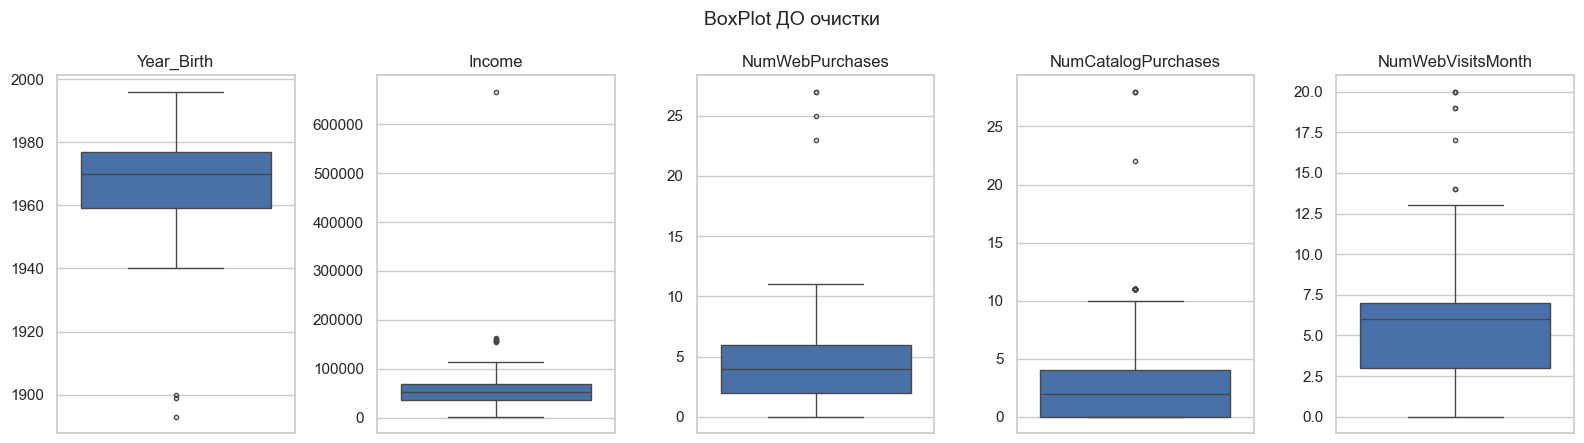

In [54]:
cols = ["Year_Birth", "Income", "NumWebPurchases", "NumCatalogPurchases", "NumWebVisitsMonth"]
fig, axes = plt.subplots(1, 5, figsize=(16, 4.5))
for ax, col in zip(axes, cols):
    sns.boxplot(y=df[col], ax=ax, color=MAIN, flierprops={"markersize": 3})
    ax.set_title(col); ax.set_ylabel("")
plt.suptitle("BoxPlot ДО очистки", fontsize=14)
plt.tight_layout(); plt.show()

**Диаграмма рассеяния** «доход → траты»: в норме чем больше доход, тем больше тратит клиент.
Точка с доходом 666 666 и обычными тратами выбивается из общей картины.

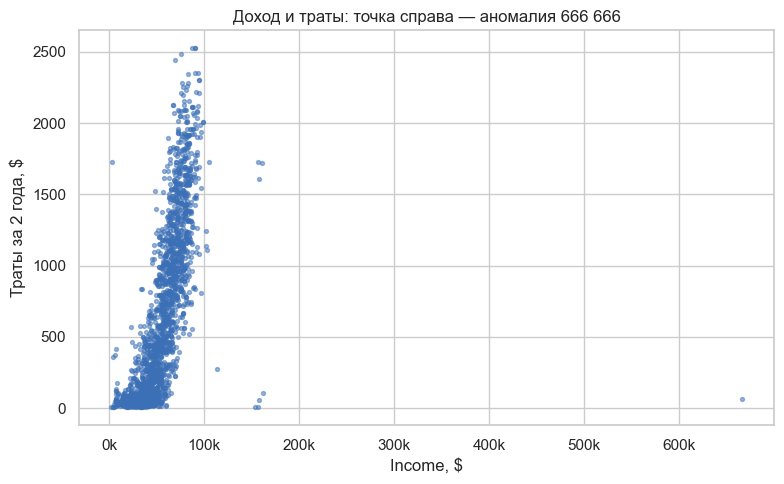

In [55]:
total_spent_raw = df[mnt_cols].sum(axis=1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["Income"], total_spent_raw, s=8, alpha=0.5, color=MAIN)
ax.set_xlabel("Income, $"); ax.set_ylabel("Траты за 2 года, $")
thousands(ax)
ax.set_title("Доход и траты: точка справа — аномалия 666 666")
plt.tight_layout(); plt.show()

### 2.5 Устранение проблем и заполнение пропусков

Принцип: **ошибочное значение → превращаем в пропуск → заполняем разумным значением**. Строки удаляем, только если в них ошибка,
которую нельзя исправить, и таких строк очень мало.
Заполняем **медианой**: в отличие от среднего, она не сдвигается от выбросов. И по возможности **медианой по группе**, а не по всем данным.

**1) Дубликаты удаляем.** Повтор одного и того же клиента искажает статистику: его траты считались бы дважды.

In [56]:
n_before = len(df)
df = df.loc[~df.drop(columns="ID").duplicated()].reset_index(drop=True)
print(f"Было {n_before} строк, удалено {n_before - len(df)}, осталось {len(df)}")

Было 2240 строк, удалено 47, осталось 2193


**2) Категории.** Приводим к осмысленному набору значений: `Alone` → `Single`; `YOLO`/`Absurd` → пропуск, затем заполняем **модой**
(самым частым значением). Для категорий медиана не имеет смысла, поэтому используется мода. `2n Cycle` → `Master`.

In [57]:
df["Marital_Status"] = df["Marital_Status"].replace({"Alone": "Single", "YOLO": np.nan, "Absurd": np.nan})
mode_status = df["Marital_Status"].mode()[0]
df["Marital_Status"] = df["Marital_Status"].fillna(mode_status)
df["Education"] = df["Education"].replace({"2n Cycle": "Master"})
print("Мода Marital_Status:", mode_status)
print(df["Marital_Status"].value_counts().to_dict())
print(df["Education"].value_counts().to_dict())

Мода Marital_Status: Married
{'Married': 849, 'Together': 570, 'Single': 474, 'Divorced': 226, 'Widow': 74}
{'Graduation': 1101, 'Master': 563, 'PhD': 475, 'Basic': 54}


**3) Год рождения.** Значения раньше 1924 (возраст больше 90) — ошибка ввода. Заменяем медианой.

In [58]:
df.loc[df["Year_Birth"] < REF_YEAR - 90, "Year_Birth"] = np.nan
df["Year_Birth"] = df["Year_Birth"].fillna(df["Year_Birth"].median()).astype(int)
print("Год рождения теперь от", df["Year_Birth"].min(), "до", df["Year_Birth"].max())

Год рождения теперь от 1940 до 1996


**4) Доход.** Значение 666 666 превращаем в пропуск, а затем заполняем все пропуски (исходные 24 и этот) **медианой дохода по образованию**.
`groupby("Education")["Income"].transform("median")` для каждой строки возвращает медиану её группы.

In [59]:
df.loc[df["Income"] > 200_000, "Income"] = np.nan
print("Медиана дохода по образованию:")
print(df.groupby("Education")["Income"].median().round(0).to_string())
df["Income"] = df["Income"].fillna(df.groupby("Education")["Income"].transform("median"))
print("\nПропусков в Income осталось:", df["Income"].isna().sum())

Медиана дохода по образованию:
Education
Basic         20744.0
Graduation    52332.0
Master        49572.0
PhD           55085.0

Пропусков в Income осталось: 0


**5) «Покупок 0, а траты есть».** Клиент не может потратить деньги, ни разу ничего не купив. Восстановить правильное число покупок
не из чего, а таких строк всего несколько (меньше 0.3%), поэтому эти строки удаляем.

In [60]:
total_purch = df[purchase_cols].sum(axis=1)
bad = (total_purch == 0) & (df[mnt_cols].sum(axis=1) > 0)
print("Удаляем строк:", bad.sum())
df = df.loc[~bad].reset_index(drop=True)

Удаляем строк: 6


**6) Ограничение хвостов (винзоризация).** Значения 23–28 покупок через сайт или каталог при медиане 2–4 — редкие единичные
экстремумы. Не удаляем их, а «прижимаем» к 99.5-му перцентилю методом `clip`.
Траты (`Mnt...`) **не трогаем**: большие траты реальны, это просто самые активные клиенты.

In [61]:
for col in ["NumWebPurchases", "NumCatalogPurchases", "NumWebVisitsMonth"]:
    hi = df[col].quantile(0.995)
    n_cut = (df[col] > hi).sum()
    df[col] = df[col].clip(upper=hi)
    print(f"{col}: верхняя граница {hi:.0f}, ограничено значений: {n_cut}")

NumWebPurchases: верхняя граница 11, ограничено значений: 4
NumCatalogPurchases: верхняя граница 11, ограничено значений: 4
NumWebVisitsMonth: верхняя граница 9, ограничено значений: 8


### 2.6 Проверка: пропусков и аномалий не осталось

In [62]:
pd.DataFrame({"до очистки": logical_checks(raw), "после очистки": logical_checks(df)})

,до очистки,после очистки
дубликаты строк (без ID),47,0
пропуски Income,24,0
возраст > 90 лет (Year_Birth < 1924),3,0
Income > 200 000,1,0
Marital_Status: YOLO / Absurd / Alone,7,0
"покупок 0, а траты > 0",6,0
NumWebPurchases > 20,4,0
NumCatalogPurchases > 20,4,0


Всего пропусков в данных: 0


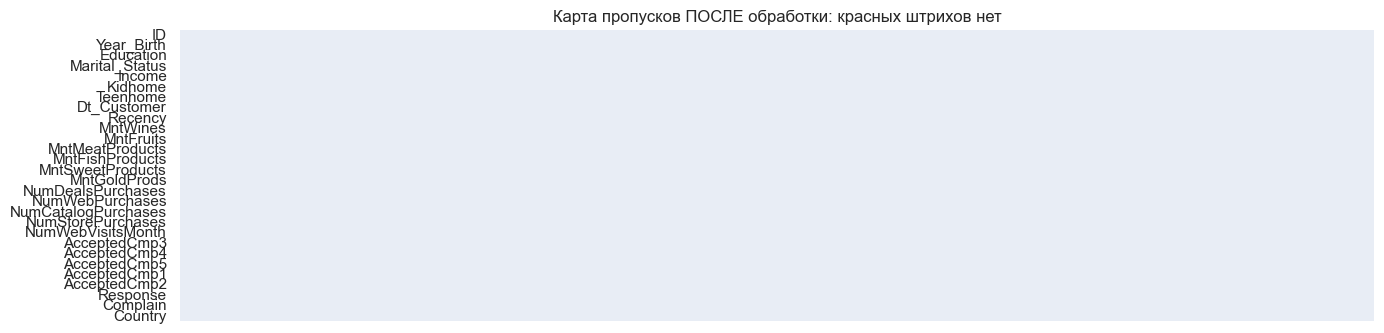

In [63]:
print("Всего пропусков в данных:", int(df.isna().sum().sum()))
fig, ax = plt.subplots(figsize=(14, 3.5))
sns.heatmap(df.isna().T, cbar=False, cmap=["#e8edf5", "#d1495b"], ax=ax, yticklabels=True, vmin=0, vmax=1)
ax.set_xticks([])
ax.set_title("Карта пропусков ПОСЛЕ обработки: красных штрихов нет")
plt.tight_layout(); plt.show()

**BoxPlot до и после.** Верхний ряд — исходные данные (серый), нижний — очищенные (синий). Каждый признак со своей шкалой.

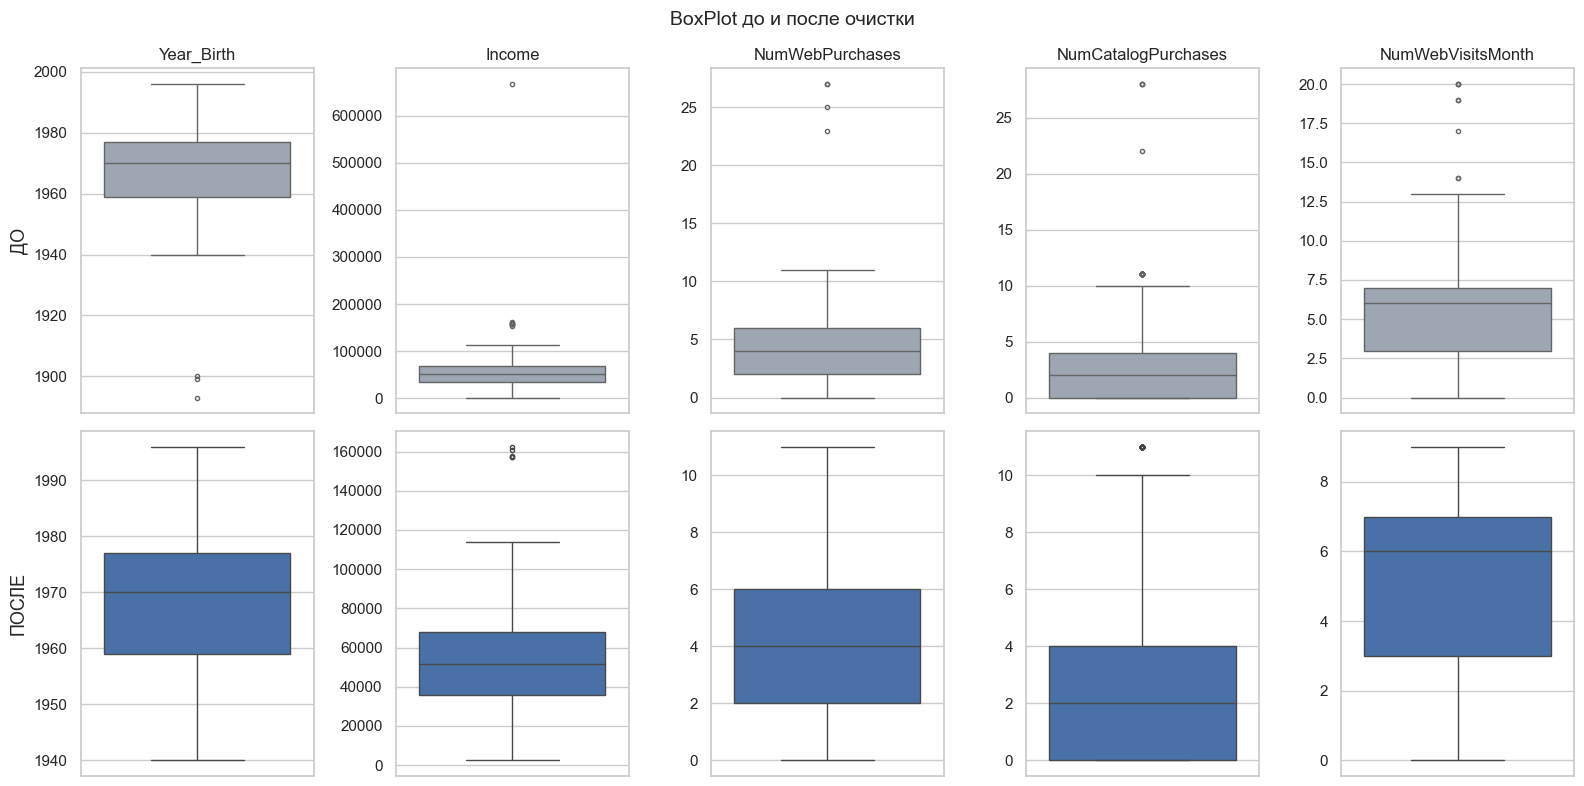

In [64]:
cols = ["Year_Birth", "Income", "NumWebPurchases", "NumCatalogPurchases", "NumWebVisitsMonth"]
fig, axes = plt.subplots(2, 5, figsize=(16, 8))
for i, col in enumerate(cols):
    sns.boxplot(y=raw[col], ax=axes[0, i], color=GREY, flierprops={"markersize": 3})
    sns.boxplot(y=df[col], ax=axes[1, i], color=MAIN, flierprops={"markersize": 3})
    axes[0, i].set_title(col); axes[0, i].set_ylabel(""); axes[1, i].set_ylabel("")
axes[0, 0].set_ylabel("ДО", fontsize=13); axes[1, 0].set_ylabel("ПОСЛЕ", fontsize=13)
plt.suptitle("BoxPlot до и после очистки", fontsize=14)
plt.tight_layout(); plt.show()

Оставшиеся точки за усами — это реальные данные (клиенты 1940-х годов рождения, доходы 100–160 тыс.), а не ошибки.
Исчезли невозможные значения, из-за которых на верхнем ряду ящики сжимались в полоску.

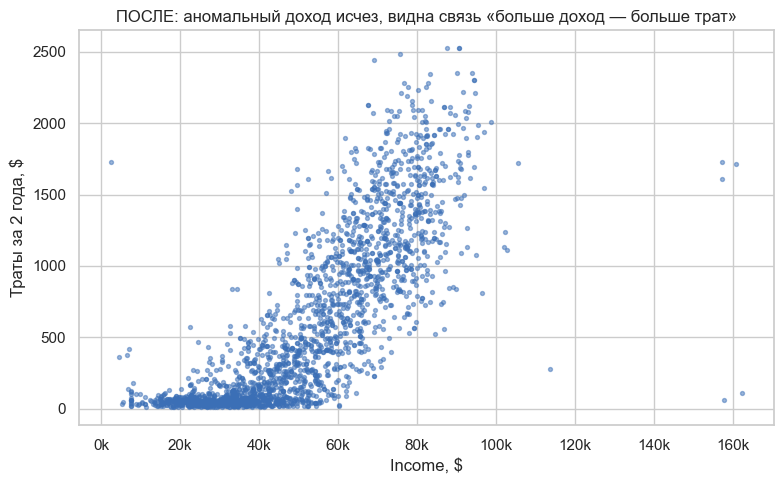

In [65]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["Income"], df[mnt_cols].sum(axis=1), s=8, alpha=0.5, color=MAIN)
ax.set_xlabel("Income, $"); ax.set_ylabel("Траты за 2 года, $")
thousands(ax)
ax.set_title("ПОСЛЕ: аномальный доход исчез, видна связь «больше доход — больше трат»")
plt.tight_layout(); plt.show()

### 2.7 Корреляции

Коэффициент корреляции Пирсона — от −1 до 1: около 0 — линейной связи нет, ближе к ±1 — сильная связь.

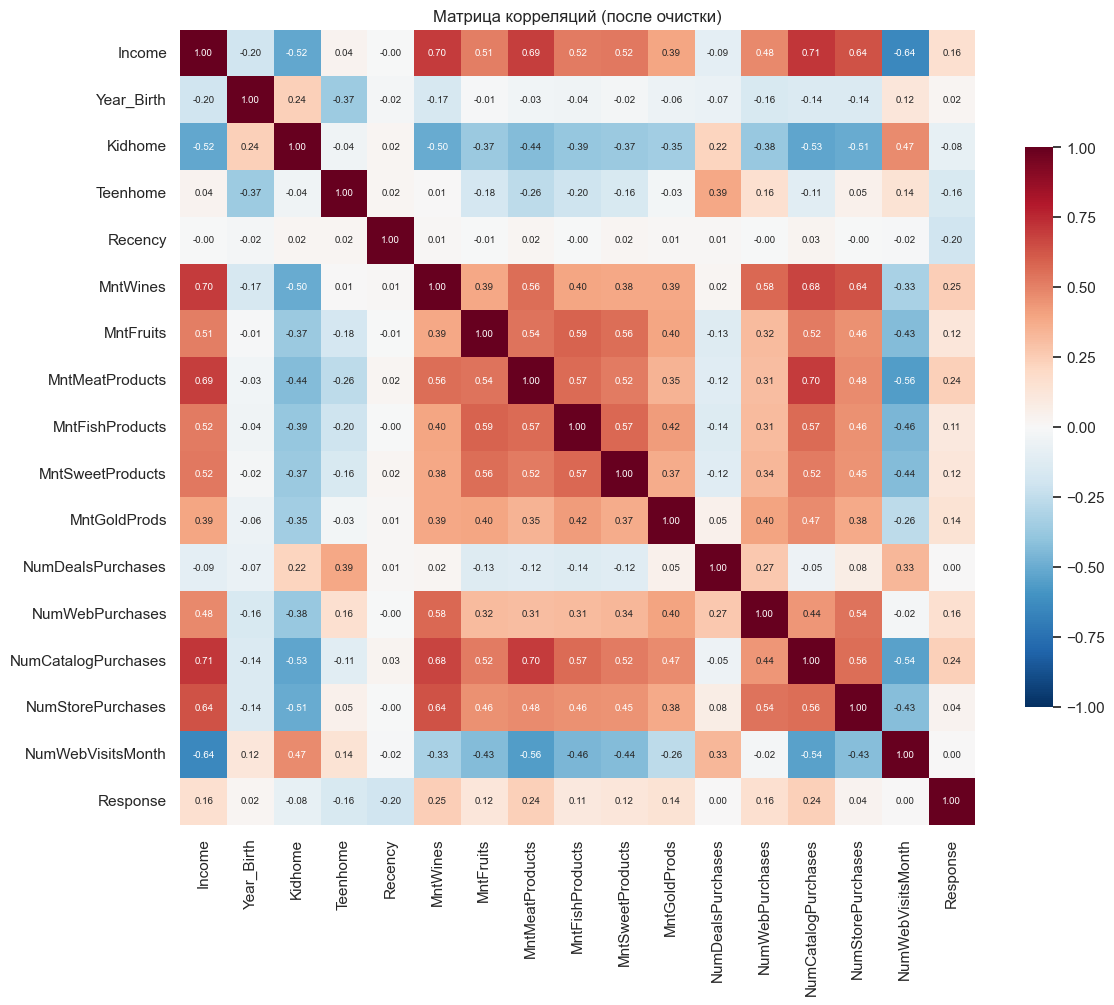

NumCatalogPurchases    0.71
MntWines               0.70
MntMeatProducts        0.69
NumStorePurchases      0.64
MntSweetProducts       0.52
MntFishProducts        0.52
Name: Income, dtype: float64

In [66]:
corr_cols = ["Income", "Year_Birth", "Kidhome", "Teenhome", "Recency"] + mnt_cols + \
            ["NumDealsPurchases"] + purchase_cols + ["NumWebVisitsMonth", "Response"]
corr = df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, square=True, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Матрица корреляций (после очистки)")
plt.tight_layout(); plt.show()
corr["Income"].drop("Income").sort_values(ascending=False).round(2).head(6)

Доход сильно связан с тратами на вино и мясо и с покупками по каталогу. Дети (`Kidhome`) связаны с тратами отрицательно:
семьи с маленькими детьми тратят меньше. А чем больше заходов на сайт, тем ниже доход: это охотники за скидками.

## 3. Новые признаки и кодирование категориальных

### 3.1 Генерация новых признаков (feature engineering)

| Признак | Формула | Зачем |
|---|---|---|
| `Age` | 2014 − Year_Birth | возраст понятнее года рождения |
| `Customer_Days` | дней от регистрации до последней даты в данных | как давно клиент с магазином |
| `Children` | Kidhome + Teenhome | общее число детей |
| `Is_Parent` | 1, если Children > 0 | есть ли дети вообще |
| `Family_Size` | взрослые (1 или 2) + дети | размер семьи |
| `Total_Spent` | сумма всех `Mnt...` | сколько клиент потратил всего |
| `Total_Purchases` | сайт + каталог + магазин | сколько раз покупал |
| `Avg_Check` | Total_Spent / Total_Purchases | средний чек |
| `Total_Accepted` | сумма `AcceptedCmp1..5` | сколько кампаний клиент принял |

In [67]:
last_date = df["Dt_Customer"].max()
df["Age"] = REF_YEAR - df["Year_Birth"]
df["Customer_Days"] = (last_date - df["Dt_Customer"]).dt.days
df["Children"] = df["Kidhome"] + df["Teenhome"]
df["Is_Parent"] = (df["Children"] > 0).astype(int)

partner = df["Marital_Status"].isin(["Married", "Together"])
df["Family_Size"] = np.where(partner, 2, 1) + df["Children"]

df["Total_Spent"] = df[mnt_cols].sum(axis=1)
df["Total_Purchases"] = df[purchase_cols].sum(axis=1)
df["Avg_Check"] = (df["Total_Spent"] / df["Total_Purchases"]).round(2)
df["Total_Accepted"] = df[[f"AcceptedCmp{i}" for i in range(1, 6)]].sum(axis=1)

new_cols = ["Age", "Customer_Days", "Children", "Is_Parent", "Family_Size",
            "Total_Spent", "Total_Purchases", "Avg_Check", "Total_Accepted"]
df[new_cols].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Age,2187.0,45.1,11.7,18.0,37.0,44.0,55.0,74.0
Customer_Days,2187.0,353.9,202.4,0.0,180.5,356.0,529.0,699.0
Children,2187.0,1.0,0.7,0.0,0.0,1.0,1.0,3.0
Is_Parent,2187.0,0.7,0.5,0.0,0.0,1.0,1.0,1.0
Family_Size,2187.0,2.6,0.9,1.0,2.0,3.0,3.0,5.0
Total_Spent,2187.0,608.0,602.6,8.0,69.0,398.0,1047.5,2525.0
Total_Purchases,2187.0,12.5,7.1,1.0,6.0,12.0,18.0,32.0
Avg_Check,2187.0,38.5,46.5,2.7,13.0,29.9,49.7,1679.0
Total_Accepted,2187.0,0.3,0.7,0.0,0.0,0.0,0.0,4.0


`np.where(условие, a, b)` — это «если / иначе» для целого столбца: где условие истинно, берётся `a`, иначе `b`.
`.dt.days` достаёт из разницы дат число дней.

Проверим, что новые признаки действительно что-то говорят о клиентах:

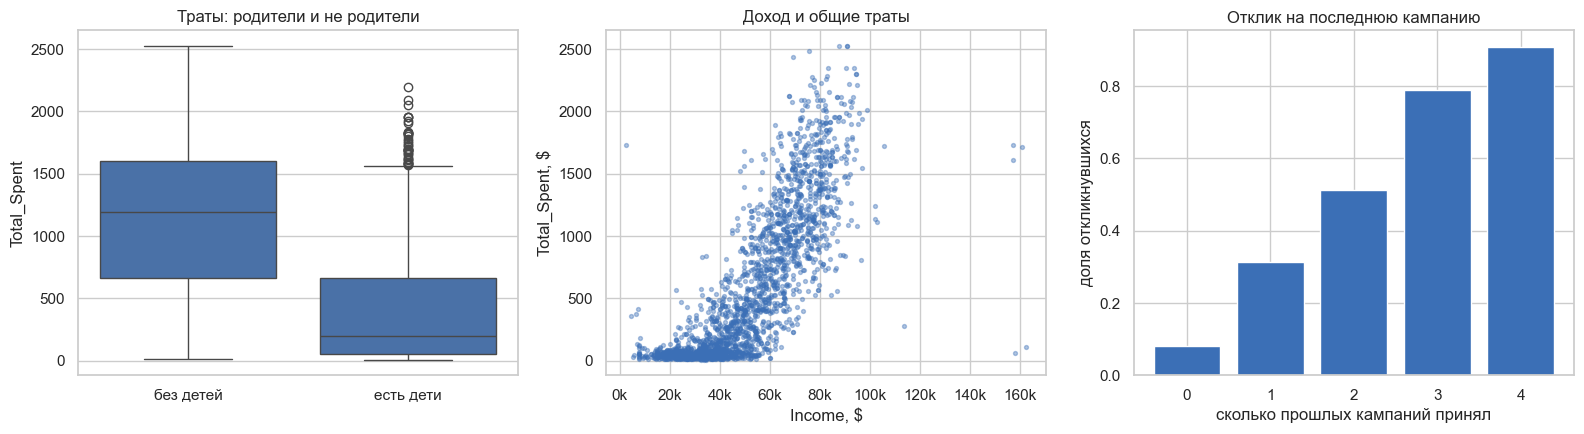

Is_Parent
без детей    1196.0
есть дети     198.0
Name: Total_Spent, dtype: float64


In [68]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=df, x="Is_Parent", y="Total_Spent", ax=axes[0], color=MAIN)
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["без детей", "есть дети"])
axes[0].set_xlabel(""); axes[0].set_title("Траты: родители и не родители")

axes[1].scatter(df["Income"], df["Total_Spent"], s=8, alpha=0.4, color=MAIN)
axes[1].set_xlabel("Income, $"); axes[1].set_ylabel("Total_Spent, $"); thousands(axes[1])
axes[1].set_title("Доход и общие траты")

resp = df.groupby("Total_Accepted")["Response"].mean()
axes[2].bar(resp.index.astype(str), resp.values, color=MAIN)
axes[2].set_xlabel("сколько прошлых кампаний принял"); axes[2].set_ylabel("доля откликнувшихся")
axes[2].set_title("Отклик на последнюю кампанию")
plt.tight_layout(); plt.show()

print(df.groupby("Is_Parent")["Total_Spent"].median().rename({0: "без детей", 1: "есть дети"}))

Клиенты без детей тратят в разы больше, чем родители, а клиенты, принимавшие прошлые кампании, гораздо чаще откликаются на новую.
Значит, признаки `Is_Parent` и `Total_Accepted` полезны для модели.

### 3.2 Кодирование категориальных признаков

Модели машинного обучения работают только с числами, поэтому текстовые категории нужно перевести в числа.
У нас три категориальных признака, и для каждого подходит свой способ:

| Признак | Есть ли порядок | Способ |
|---|---|---|
| `Education` | да: Basic < Graduation < Master < PhD | **порядковое кодирование** (OrdinalEncoder) |
| `Marital_Status` | нет, но по смыслу две группы: с партнёром / без | **бинаризация** → `Living_With_Partner` |
| `Country` | нет, 8 стран | **One-Hot Encoding** |

**Порядковое (ordinal) кодирование.** У образования есть естественный порядок, поэтому числа 0, 1, 2, 3 здесь осмысленны:
PhD действительно «выше» Basic. Порядок категорий задаём явно, иначе энкодер расставит их по алфавиту.

In [69]:
edu_order = [["Basic", "Graduation", "Master", "PhD"]]
ord_enc = OrdinalEncoder(categories=edu_order)
df["Education_Level"] = ord_enc.fit_transform(df[["Education"]]).astype(int)
df[["Education", "Education_Level"]].drop_duplicates().sort_values("Education_Level")

,Education,Education_Level
53,Basic,0
0,Graduation,1
6,Master,2
5,PhD,3


**Бинаризация.** `Marital_Status` сводим к двум значениям: живёт с партнёром (`Married`, `Together`) → 1, один (`Single`, `Divorced`, `Widow`) → 0.

In [70]:
df["Living_With_Partner"] = df["Marital_Status"].isin(["Married", "Together"]).astype(int)
pd.crosstab(df["Marital_Status"], df["Living_With_Partner"])

Living_With_Partner,0,1
Marital_Status,,
Divorced,223,0
Married,0,847
Single,473,0
Together,0,570
Widow,74,0


**Бинаризация числового признака по порогу** (`Binarizer`): значение выше порога → 1, иначе → 0.
Признак `High_Income`: доход выше медианы.

In [71]:
income_median = df["Income"].median()
binarizer = Binarizer(threshold=income_median)
df["High_Income"] = binarizer.fit_transform(df[["Income"]]).astype(int).ravel()
print(f"Порог (медиана дохода): {income_median:,.0f} $")
df["High_Income"].value_counts()

Порог (медиана дохода): 51,537 $


High_Income
0    1094
1    1093
Name: count, dtype: int64

**One-Hot Encoding (OHE).** Признак с k категориями превращается в k столбцов из 0 и 1, в каждой строке ровно одна единица.
Просто пронумеровать страны нельзя: модель решила бы, что США (7) «больше» Испании (5), хотя порядка у стран нет.

Ниже показаны два способа: `pd.get_dummies` (pandas) и `OneHotEncoder` (sklearn).

In [72]:
# Способ 1: pandas
country_dummies = pd.get_dummies(df["Country"], prefix="Country", dtype=int)
print(country_dummies.head())

# Способ 2: sklearn — энкодер запоминает категории (fit), а потом одинаково кодирует новые данные (transform)
ohe = OneHotEncoder(handle_unknown="ignore")
encoded = ohe.fit_transform(df[["Country"]]).toarray().astype(int)
print("\nКатегории, найденные OneHotEncoder:", list(ohe.categories_[0]))
print("Результаты двух способов совпадают:", (encoded == country_dummies.values).all())

   Country_AUS  Country_CA  Country_GER  Country_IND  Country_ME  Country_SA  Country_SP  Country_US
0            0           0            0            0           0           0           1           0
1            0           1            0            0           0           0           0           0
2            0           0            0            0           0           0           0           1
3            1           0            0            0           0           0           0           0
4            0           0            0            0           0           0           1           0

Категории, найденные OneHotEncoder: ['AUS', 'CA', 'GER', 'IND', 'ME', 'SA', 'SP', 'US']
Результаты двух способов совпадают: True


Добавляем закодированные столбцы в таблицу и убираем исходные текстовые признаки и дату: в закодированном виде они уже есть.

In [73]:
df_enc = pd.concat([df, country_dummies], axis=1).drop(columns=["Education", "Marital_Status", "Country", "Dt_Customer"])
print("Итоговый размер:", df_enc.shape)
print("Нечисловых столбцов осталось:", list(df_enc.select_dtypes(exclude="number").columns))
df_enc.head()

Итоговый размер: (2187, 44)
Нечисловых столбцов осталось: []


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Age,Customer_Days,Children,Is_Parent,Family_Size,Total_Spent,Total_Purchases,Avg_Check,Total_Accepted,Education_Level,Living_With_Partner,High_Income,Country_AUS,Country_CA,Country_GER,Country_IND,Country_ME,Country_SA,Country_SP,Country_US
0,1826,1970,84835.0,0,0,0,189,104,379,111,189,218,1,4,4,6,1,0,0,0,0,0,1,0,44,13,0,0,1,1190,14,85.00,0,1,0,1,0,0,0,0,0,0,1,0
1,1,1961,57091.0,0,0,0,464,5,64,7,0,37,1,7,3,7,5,0,0,0,0,1,1,0,53,14,0,0,1,577,17,33.94,1,1,0,1,0,1,0,0,0,0,0,0
2,10476,1958,67267.0,0,1,0,134,11,59,15,2,30,1,3,2,5,2,0,0,0,0,0,0,0,56,47,1,1,3,251,10,25.10,0,1,1,1,0,0,0,0,0,0,0,1
3,1386,1967,32474.0,1,1,0,10,0,1,0,0,0,1,1,0,2,7,0,0,0,0,0,0,0,47,49,2,1,4,11,3,3.67,0,1,1,0,1,0,0,0,0,0,0,0
4,5371,1989,21474.0,1,0,0,6,16,24,11,0,34,2,3,1,2,7,1,0,0,0,0,1,0,25,82,1,1,2,91,6,15.17,1,1,0,0,0,0,0,0,0,0,1,0


## 4. Стандартизация и нормализация

Признаки в разных масштабах: `Income` — десятки тысяч, `Kidhome` — 0…2, `Avg_Check` — десятки.
Алгоритмы, которые считают расстояния (kNN, k-means, SVM) или используют градиентный спуск (линейные модели, нейросети),
начинают ориентироваться на признак с большими числами просто из-за его масштаба.

| Метод | Формула | Результат | Когда |
|---|---|---|---|
| **Стандартизация** (`StandardScaler`) | z = (x − mean) / std | среднее 0, стандартное отклонение 1 | по умолчанию: линейные модели, SVM, PCA |
| **Нормализация** (`MinMaxScaler`) | x' = (x − min) / (max − min) | все значения в [0; 1] | нужен фиксированный диапазон: нейросети, kNN |

**Не масштабируем:** `ID` (это не признак), `Response` (целевая переменная), бинарные признаки 0/1 — они уже в нужном масштабе.

In [74]:
binary_cols = [c for c in df_enc.columns if set(df_enc[c].unique()) <= {0, 1}]
scale_cols = [c for c in df_enc.columns if c not in ["ID", "Response"] + binary_cols]
print("Бинарные (не масштабируем):", binary_cols)
print("\nМасштабируем:", scale_cols)

Бинарные (не масштабируем): ['AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Response', 'Complain', 'Is_Parent', 'Living_With_Partner', 'High_Income', 'Country_AUS', 'Country_CA', 'Country_GER', 'Country_IND', 'Country_ME', 'Country_SA', 'Country_SP', 'Country_US']

Масштабируем: ['Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'Age', 'Customer_Days', 'Children', 'Family_Size', 'Total_Spent', 'Total_Purchases', 'Avg_Check', 'Total_Accepted', 'Education_Level']


In [75]:
std_scaler = StandardScaler()
df_std = df_enc.copy()
df_std[scale_cols] = std_scaler.fit_transform(df_enc[scale_cols])

mm_scaler = MinMaxScaler()
df_mm = df_enc.copy()
df_mm[scale_cols] = mm_scaler.fit_transform(df_enc[scale_cols])

show = ["Income", "Age", "Total_Spent", "Kidhome"]
pd.concat({
    "исходные": df_enc[show].agg(["mean", "std", "min", "max"]),
    "StandardScaler": df_std[show].agg(["mean", "std", "min", "max"]),
    "MinMaxScaler": df_mm[show].agg(["mean", "std", "min", "max"]),
}).round(3)

Income     Age  Total_Spent  Kidhome
исходные       mean   51995.486  45.113      607.978    0.444
               std    21097.196  11.706      602.650    0.539
               min     2447.000  18.000        8.000    0.000
               max   162397.000  74.000     2525.000    2.000
StandardScaler mean       0.000  -0.000       -0.000    0.000
               std        1.000   1.000        1.000    1.000
               min       -2.349  -2.317       -0.996   -0.825
               max        5.234   2.468        3.182    2.889
MinMaxScaler   mean       0.310   0.484        0.238    0.222
               std        0.132   0.209        0.239    0.269
               min        0.000   0.000        0.000    0.000
               max        1.000   1.000        1.000    1.000

После `StandardScaler` у каждого признака среднее 0 и std 1, после `MinMaxScaler` — min 0 и max 1.
**Форма распределения при масштабировании не меняется**, меняется только шкала по оси X:

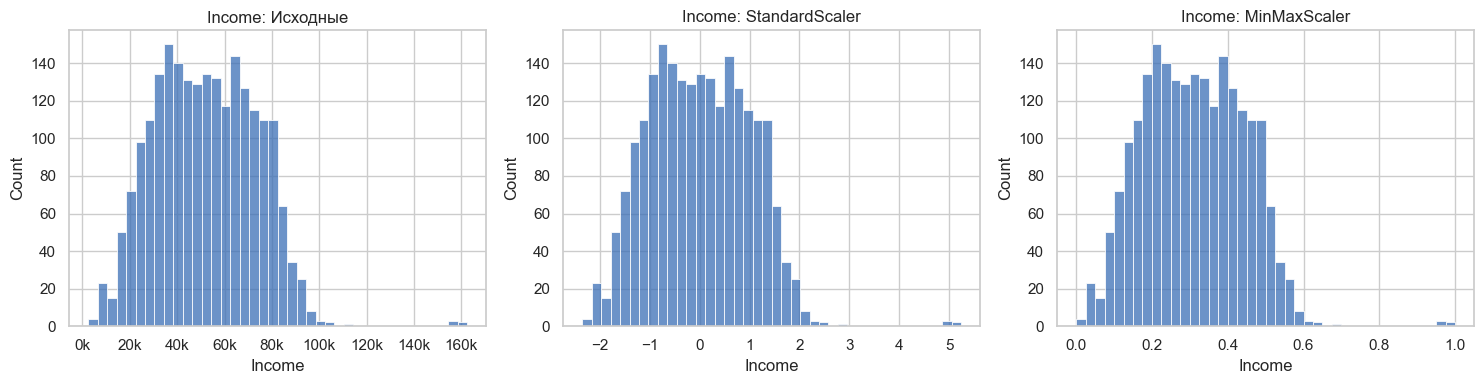

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, data, title in zip(axes, [df_enc, df_std, df_mm], ["Исходные", "StandardScaler", "MinMaxScaler"]):
    sns.histplot(data["Income"], bins=40, ax=ax, color=MAIN)
    ax.set_title(f"Income: {title}")
    if title == "Исходные":
        thousands(ax)
plt.tight_layout(); plt.show()

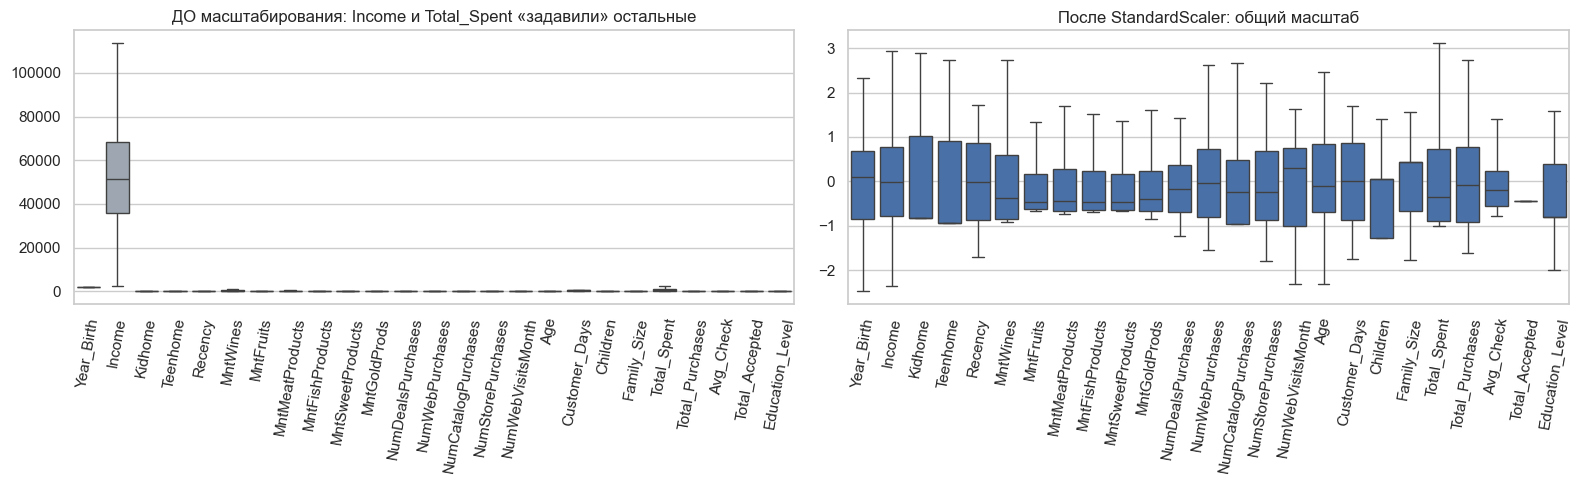

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df_enc[scale_cols], ax=axes[0], color=GREY, showfliers=False)
axes[0].set_title("ДО масштабирования: Income и Total_Spent «задавили» остальные")
axes[0].tick_params(axis="x", rotation=80)
sns.boxplot(data=df_std[scale_cols], ax=axes[1], color=MAIN, showfliers=False)
axes[1].set_title("После StandardScaler: общий масштаб")
axes[1].tick_params(axis="x", rotation=80)
plt.tight_layout(); plt.show()

> **Важно для будущих работ с моделями.** Scaler «учится» (`fit`) только на обучающей выборке, а к тестовой применяется `transform`
> с уже найденными mean и std. Иначе в модель «утечёт» информация из теста (data leakage). Здесь моделей нет, только подготовка данных,
> поэтому `fit` делаем на всём датасете.

Сохраняем результаты (файлы появятся в папке `output` рядом с ноутбуком):

In [78]:
import os
os.makedirs("output", exist_ok=True)
df_enc.to_csv("output/marketing_clean.csv", index=False)
df_std.to_csv("output/marketing_standardized.csv", index=False)
df_mm.to_csv("output/marketing_normalized.csv", index=False)
print("Сохранено:", os.listdir("output"))
print("Итоговый датасет:", df_std.shape)

Сохранено: ['marketing_normalized.csv', 'marketing_standardized.csv', 'marketing_clean.csv']
Итоговый датасет: (2187, 44)


## Выводы

1. **Импорт.** Датасет из 2240 клиентов загружен из zip-архива функцией `pd.read_csv`. Имена столбцов очищены от пробелов,
   доход из строки `"$84,835.00"` переведён в число, дата регистрации — в тип `datetime`.
2. **Пропуски и аномалии** найдены методами IQR и Z-оценки, на гистограммах, BoxPlot и диаграмме рассеяния, а также логическими проверками:
   47 полных дубликатов, 24 пропуска дохода, доход 666 666, годы рождения 1893–1900, бессмысленные категории `YOLO` / `Absurd`,
   клиенты с тратами, но без покупок. Дубликаты и противоречивые строки удалены, ошибочные значения заменены медианами
   (доход — по группе образования), категории приведены к единому виду, редкие экстремумы ограничены 99.5-м перцентилем.
   Повторные проверки и графики «после» подтверждают, что пропусков и аномалий не осталось.
3. **Новые признаки:** `Age`, `Customer_Days`, `Children`, `Is_Parent`, `Family_Size`, `Total_Spent`, `Total_Purchases`, `Avg_Check`,
   `Total_Accepted`, а также `Living_With_Partner` и `High_Income`. **Кодирование:** порядковое (`Education` → `Education_Level`),
   бинаризация (`Marital_Status` → `Living_With_Partner`), пороговая бинаризация `Binarizer` (`High_Income`),
   One-Hot Encoding (`Country`, двумя способами).
4. **Масштабирование:** стандартизация `StandardScaler` (mean = 0, std = 1) и нормализация `MinMaxScaler` (диапазон [0; 1]).
   Данные готовы к обучению моделей.